In [1]:
%pip install pandas scikit-learn matplotlib shap ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split

# Load the UCI Auto MPG dataset
auto_mpg = fetch_ucirepo(id=9)

features = [
    "weight",
    "horsepower",
    "displacement",
    "acceleration",
    "model_year",
]

data = auto_mpg.data.original[features + ["mpg"]].copy()

rows_before = len(data)
data = data.dropna(subset=features + ["mpg"])

X = data[features]
y = data["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Rows removed due to missing values: {rows_before - len(data)}")
print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")
display(data.head())

Rows removed due to missing values: 6
Training observations: 313
Test observations: 79


,weight,horsepower,displacement,acceleration,model_year,mpg
0,3504,130.0,307.0,12.0,70,18.0
1,3693,165.0,350.0,11.5,70,15.0
2,3436,150.0,318.0,11.0,70,18.0
3,3433,150.0,304.0,12.0,70,16.0
4,3449,140.0,302.0,10.5,70,17.0


In [3]:
from math import sqrt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Test MSE: {mse:.2f} mpg²")
print(f"Test RMSE: {rmse:.2f} mpg")
print(f"Test R²: {r2:.3f}")

Test MSE: 10.58 mpg²
Test RMSE: 3.25 mpg
Test R²: 0.793


c:\Users\User\CN6005 Portfolio\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 313 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=313 when initializing the masker.


,Mean absolute SHAP value
weight,5.125
model_year,2.587
acceleration,0.113
displacement,0.072
horsepower,0.063


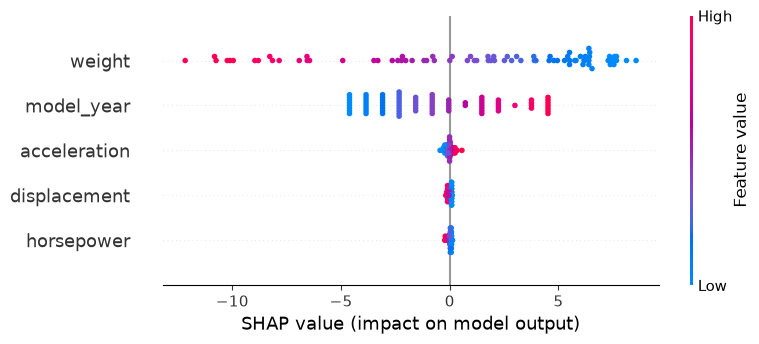

In [4]:
import pandas as pd
import shap

# Use training data as the background and explain held-out predictions
explainer = shap.LinearExplainer(model, X_train)
shap_values = explainer(X_test)

# Rank features by the average magnitude of their contributions
importance = pd.Series(
    abs(shap_values.values).mean(axis=0),
    index=X_test.columns,
    name="Mean absolute SHAP value",
).sort_values(ascending=False)

display(importance.to_frame().round(3))

# Show the direction and size of each feature's contributions
shap.plots.beeswarm(shap_values)

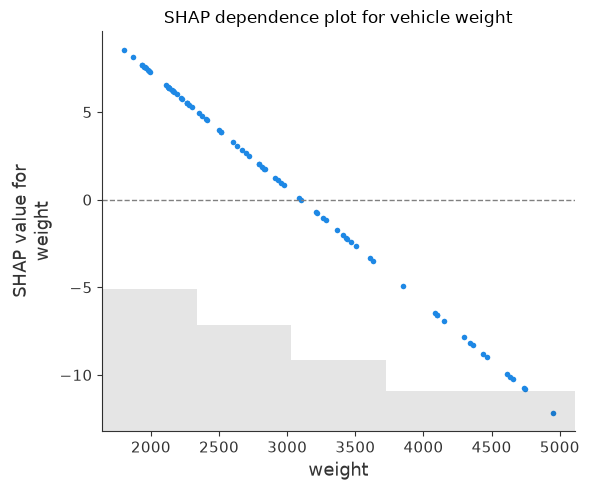

In [5]:
import matplotlib.pyplot as plt

shap.plots.scatter(shap_values[:, "weight"], show=False)
plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.title("SHAP dependence plot for vehicle weight")
plt.tight_layout()
plt.show()